# Bài 1 · Bức xạ vật đen
*Episode 1 · Blackbody radiation*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/01_blackbody.ipynb)

Từ phổ của vật đen tuyệt đối đến bức xạ nền vi sóng vũ trụ: hãy chạy lần lượt các ô để kiểm chứng định luật Planck bằng tính toán và dữ liệu thật.
*From the spectrum of an ideal blackbody to the cosmic microwave background: run the cells in order to test Planck's law with calculations and real data.*

## 1. Một công thức nối hai giới hạn
*One formula connects two limits*

Với bước sóng $\lambda$ tính bằng mét và nhiệt độ $T$ tính bằng kelvin, đặt $x=hc/(\lambda k_B T)$. Ba hàm dưới đây cho độ chói phổ $B_\lambda$ theo đơn vị W·sr⁻¹·m⁻³. Dùng $T=5800$ K và khoảng 100–3000 nm như mô phỏng; trục dọc giới hạn ở $1{,}3$ lần đỉnh Planck để thấy đường Rayleigh–Jeans vọt khỏi khung ở bước sóng ngắn.
*With wavelength $\lambda$ in metres and temperature $T$ in kelvin, let $x=hc/(\lambda k_B T)$. The three functions below give spectral radiance $B_\lambda$ in W·sr⁻¹·m⁻³. Use $T=5800$ K and 100–3000 nm as in the simulation; clip the vertical axis at $1.3$ times the Planck peak to show Rayleigh–Jeans shooting out of frame at short wavelengths.*

Long-wavelength RJ relative error (1 mm, 5800 K): 1.241e-03
Short-wavelength Wien relative error (300 nm, 3000 K): 1.141e-07


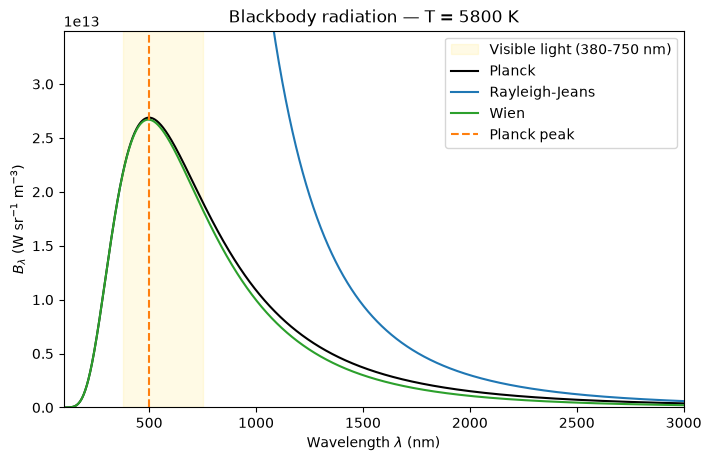

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import h, c, k as k_B, Wien, sigma
from scipy.integrate import quad
from scipy.optimize import brentq, curve_fit
from io import StringIO


def planck(wavelength, temperature):
    """B_lambda in W sr^-1 m^-3; wavelength in m, temperature in K."""
    wavelength = np.asarray(wavelength, dtype=float)
    x = h * c / (wavelength * k_B * temperature)
    return (2 * h * c**2 / wavelength**5) / np.expm1(x)


def rayleigh_jeans(wavelength, temperature):
    """Long-wavelength approximation to B_lambda, in SI units."""
    wavelength = np.asarray(wavelength, dtype=float)
    return 2 * c * k_B * temperature / wavelength**4


def wien(wavelength, temperature):
    """Short-wavelength approximation to B_lambda, in SI units."""
    wavelength = np.asarray(wavelength, dtype=float)
    x = h * c / (wavelength * k_B * temperature)
    return (2 * h * c**2 / wavelength**5) * np.exp(-x)


T = 5800
# Same relative-error checks and test points as check.mjs.
rj_error = abs(rayleigh_jeans(1e-3, T) / planck(1e-3, T) - 1)
wien_error = abs(wien(300e-9, 3000) / planck(300e-9, 3000) - 1)
assert rj_error < 2e-3
assert wien_error < 1e-6
print(f"Long-wavelength RJ relative error (1 mm, {T} K): {rj_error:.3e}")
print(f"Short-wavelength Wien relative error (300 nm, 3000 K): {wien_error:.3e}")

wavelengths_nm = np.linspace(100, 3000, 2000)
wavelengths = wavelengths_nm * 1e-9
peak_wavelength = Wien / T
fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
ax.axvspan(380, 750, alpha=0.10, color="gold", label="Visible light (380-750 nm)")
ax.plot(wavelengths_nm, planck(wavelengths, T), label="Planck", color="black")
ax.plot(wavelengths_nm, rayleigh_jeans(wavelengths, T), label="Rayleigh-Jeans")
ax.plot(wavelengths_nm, wien(wavelengths, T), label="Wien", color="tab:green")
ax.axvline(peak_wavelength * 1e9, ls="--", color="tab:orange", label="Planck peak")
ax.set(xlim=(100, 3000), ylim=(0, 1.3 * planck(peak_wavelength, T)),
       xlabel=r"Wavelength $\lambda$ (nm)", ylabel=r"$B_\lambda$ (W sr$^{-1}$ m$^{-3}$)",
       title=f"Blackbody radiation — T = {T} K")
ax.legend()
plt.show()

## 2. Định luật dịch chuyển Wien
*Wien's displacement law*

Đạo hàm $B_\lambda$ theo $\lambda$ cho phương trình $x=5(1-e^{-x})$. Tìm nghiệm dương khác 0 bằng `brentq`, rồi tính $b=hc/(xk_B)$ và $\lambda_{\max}=b/T$. Đây là đỉnh của phổ **theo bước sóng**; đỉnh của $B_\nu$ không cho cùng bước sóng khi đổi bằng $\lambda=c/\nu$.
*Differentiating $B_\lambda$ with respect to $\lambda$ gives $x=5(1-e^{-x})$. Find the nonzero positive root with `brentq`, then compute $b=hc/(xk_B)$ and $\lambda_{\max}=b/T$. This is the peak of the spectrum **per unit wavelength**; the peak of $B_\nu$ gives a different wavelength when converted using $\lambda=c/\nu$.*

In [2]:
# The bracket excludes the trivial root x = 0.
x_peak = brentq(lambda x: x - 5 * (1 - np.exp(-x)), 1, 6)
assert abs(x_peak - 4.965) < 5e-4  # Agreement to three decimal places.
b = h * c / (x_peak * k_B)
b_error = abs(b / Wien - 1)
assert b_error < 1e-6
assert abs(b / 2.897771955e-3 - 1) < 1e-6
print(f"x = {x_peak:.9f}")
print(f"b = {b:.12e} m K; scipy.constants.Wien = {Wien:.12e} m K")
print(f"Relative error: {b_error:.3e}")
print(f"Peak at {T} K: {b / T * 1e9:.3f} nm")

x = 4.965114232
b = 2.897771955185e-03 m K; scipy.constants.Wien = 2.897771955185e-03 m K
Relative error: 4.441e-16
Peak at 5800 K: 499.616 nm


## 3. Định luật Stefan–Boltzmann
*The Stefan–Boltzmann law*

Công suất phát trên một đơn vị diện tích là $M=\pi\int_0^\infty B_\lambda\,d\lambda$; hệ số $\pi$ đến từ tích phân góc trên bán cầu. Đổi biến $x=hc/(\lambda k_B T)$ để tích phân ổn định hơn:
*The emitted power per unit area is $M=\pi\int_0^\infty B_\lambda\,d\lambda$; the factor $\pi$ comes from the angular integral over a hemisphere. Substitute $x=hc/(\lambda k_B T)$ for stable integration:*

$$M=\frac{2\pi k_B^4T^4}{c^2h^3}\int_0^\infty\frac{x^3}{e^x-1}\,dx=\sigma T^4,\qquad
\sigma=\frac{2\pi^5k_B^4}{15c^2h^3}.$$

In [3]:
def thermal_integrand(x):
    # Equivalent to x**3 / expm1(x), without overflow at large x.
    if x == 0:
        return 0.0
    return x**3 * np.exp(-x) / (-np.expm1(-x))


integral, integral_error = quad(thermal_integrand, 0, np.inf,
                                epsabs=1e-11, epsrel=1e-11)
prefactor = 2 * np.pi * k_B**4 * T**4 / (c**2 * h**3)
emitted_power = prefactor * integral
expected_power = sigma * T**4
power_error = abs(emitted_power / expected_power - 1)
sigma_closed = 2 * np.pi**5 * k_B**4 / (15 * c**2 * h**3)
assert power_error < 1e-6
assert abs(sigma_closed / sigma - 1) < 1e-6
print(f"Dimensionless integral = {integral:.12f}; pi^4/15 = {np.pi**4 / 15:.12f}")
print(f"Estimated quadrature error in power: {prefactor * integral_error:.3e} W/m^2")
print(f"Integrated power: {emitted_power:.6e} W/m^2 = {emitted_power / 1e6:.3f} MW/m^2")
print(f"sigma T^4:        {expected_power:.6e} W/m^2; relative error = {power_error:.3e}")
print(f"Closed-form sigma: {sigma_closed:.12e} W m^-2 K^-4")
print(f"SciPy sigma:       {sigma:.12e} W m^-2 K^-4")

Dimensionless integral = 6.493939402267; pi^4/15 = 6.493939402267
Estimated quadrature error in power: 1.265e-04 W/m^2
Integrated power: 6.416877e+07 W/m^2 = 64.169 MW/m^2
sigma T^4:        6.416877e+07 W/m^2; relative error = 1.110e-16
Closed-form sigma: 5.670374419184e-08 W m^-2 K^-4
SciPy sigma:       5.670374419184e-08 W m^-2 K^-4


## 4. Dữ liệu thật: bức xạ nền vi sóng vũ trụ
*Real data: the cosmic microwave background*

Bức xạ nền vi sóng vũ trụ (CMB) là ánh sáng từ vũ trụ sơ khai, phát ra và bắt đầu truyền tự do khoảng 380 000 năm sau Big Bang ([NASA](https://science.nasa.gov/astrophysics/programs/physics-of-the-cosmos/big-bang-and-the-evolution-of-the-universe/)). Đây là phổ vật đen được đo chính xác nhất trong tự nhiên: phân tích COBE/FIRAS của [Fixsen và cộng sự (1996), ApJ 473, 576](https://doi.org/10.1086/178173) cho độ lệch RMS dưới 50 phần triệu so với cường độ đỉnh, không phải bằng chứng rằng mọi sai lệch đều bằng 0.
*The cosmic microwave background (CMB) is light from the early universe, emitted and released to travel freely about 380,000 years after the Big Bang ([NASA](https://science.nasa.gov/astrophysics/programs/physics-of-the-cosmos/big-bang-and-the-evolution-of-the-universe/)). It is the most precisely measured blackbody spectrum in nature: the COBE/FIRAS analysis by [Fixsen et al. (1996), ApJ 473, 576](https://doi.org/10.1086/178173) found RMS deviations below 50 parts per million of the peak intensity, not proof that every deviation is zero.*

Bảng 43 dòng dưới đây được nhúng nguyên từ [NASA LAMBDA, FIRAS monopole spectrum v1](https://lambda.gsfc.nasa.gov/data/cobe/firas/monopole_spec/firas_monopole_spec_v1.txt), nên không cần mạng khi chạy. Theo header, cột 2 là phổ vật đen $2{,}725$ K cộng phần dư từ Bảng 4 của Fixsen (1996); file cũng dẫn Fixsen & Mather (2002). Đó không phải dữ liệu thô hay phép đo nhiệt độ độc lập mới.
*The 43 rows below are embedded directly from [NASA LAMBDA, FIRAS monopole spectrum v1](https://lambda.gsfc.nasa.gov/data/cobe/firas/monopole_spec/firas_monopole_spec_v1.txt), so execution needs no network. The header says column 2 is a $2.725$ K blackbody plus residuals from Table 4 of Fixsen (1996); the file also cites Fixsen & Mather (2002). These are neither raw data nor a new independent temperature measurement.*

In [4]:
# All five columns, with the original numeric values and units from the file header:
# 1: frequency (wavenumber), cm^-1
# 2: monopole intensity, MJy/sr (2.725 K blackbody + column 3 residual)
# 3: monopole residual, kJy/sr
# 4: spectrum uncertainty (1 sigma), kJy/sr
# 5: modeled Galactic polar intensity, kJy/sr (not an extra subtraction)
# Source: https://lambda.gsfc.nasa.gov/data/cobe/firas/monopole_spec/firas_monopole_spec_v1.txt
firas_table = """
  2.27   200.723      5     14      4
  2.72   249.508      9     19      3
  3.18   293.024     15     25     -1
  3.63   327.770      4     23     -1
  4.08   354.081     19     22      3
  4.54   372.079    -30     21      6
  4.99   381.493    -30     18      8
  5.45   383.478    -10     18      8
  5.90   378.901     32     16     10
  6.35   368.833      4     14     10
  6.81   354.063     -2     13     12
  7.26   336.278     13     12     20
  7.71   316.076    -22     11     25
  8.17   293.924      8     10     30
  8.62   271.432      8     11     36
  9.08   248.239    -21     12     41
  9.53   225.940      9     14     46
  9.98   204.327     12     16     57
 10.44   183.262     11     18     65
 10.89   163.830    -29     22     73
 11.34   145.750    -46     22     93
 11.80   128.835     58     23     98
 12.25   113.568      6     23    105
 12.71    99.451     -6     23    121
 13.16    87.036      6     22    135
 13.61    75.876    -17     21    147
 14.07    65.766      6     20    160
 14.52    57.008     26     19    178
 14.97    49.223    -12     19    199
 15.43    42.267    -19     19    221
 15.88    36.352      8     21    227
 16.34    31.062      7     23    250
 16.79    26.580     14     26    275
 17.24    22.644    -33     28    295
 17.70    19.255      6     30    312
 18.15    16.391     26     32    336
 18.61    13.811    -26     33    363
 19.06    11.716     -6     35    405
 19.51     9.921      8     41    421
 19.97     8.364     26     55    435
 20.42     7.087     57     88    477
 20.87     5.801   -116    155    519
 21.33     4.523   -432    282    573
"""
firas = np.loadtxt(StringIO(firas_table))
assert firas.shape == (43, 5)

File ghi “frequency” theo cm⁻¹, tức số sóng $\tilde\nu$: đổi sang Hz bằng $\nu=100c\tilde\nu$. Cường độ đã là $B_\nu$, không phải mật độ theo số sóng: $1$ Jy $=10^{-26}$ W·m⁻²·Hz⁻¹, nên nhân MJy/sr với $10^{-20}$ và kJy/sr với $10^{-23}$. Khớp $B_\nu=2h\nu^3/[c^2(e^{h\nu/(k_BT)}-1)]$ theo một tham số $T$.
*The file labels wavenumber $\tilde\nu$ in cm⁻¹ as “frequency”: convert to Hz using $\nu=100c\tilde\nu$. Intensity is already $B_\nu$, not density per wavenumber: $1$ Jy $=10^{-26}$ W·m⁻²·Hz⁻¹, so multiply MJy/sr by $10^{-20}$ and kJy/sr by $10^{-23}$. Fit $B_\nu=2h\nu^3/[c^2(e^{h\nu/(k_BT)}-1)]$ with $T$ as the single parameter.*

Coi sai số từng điểm là độc lập và dùng `absolute_sigma=True`. $\sigma_T$ in ra chỉ là sai số hình thức của phép fit, chưa gồm tương quan giữa các kênh hay sai số hiệu chuẩn tuyệt đối; bài báo 1996 báo $2{,}728\pm0{,}004$ K (độ tin cậy 95 %). Thanh sai số rất nhỏ trên đồ thị phổ; đồ thị phần dư bên dưới phóng đại chúng.
*Treat point uncertainties as independent and use `absolute_sigma=True`. The printed $\sigma_T$ is only the formal fit uncertainty, excluding channel correlations and absolute calibration uncertainty; the 1996 paper reported $2.728\pm0.004$ K (95% confidence). Error bars are tiny on the spectrum plot; the residual panel below enlarges them.*

CMB temperature: T = 2.725015332 +/- 0.000007578 K (formal 1-sigma)
chi^2 / dof = 45.10 / 42 = 1.074


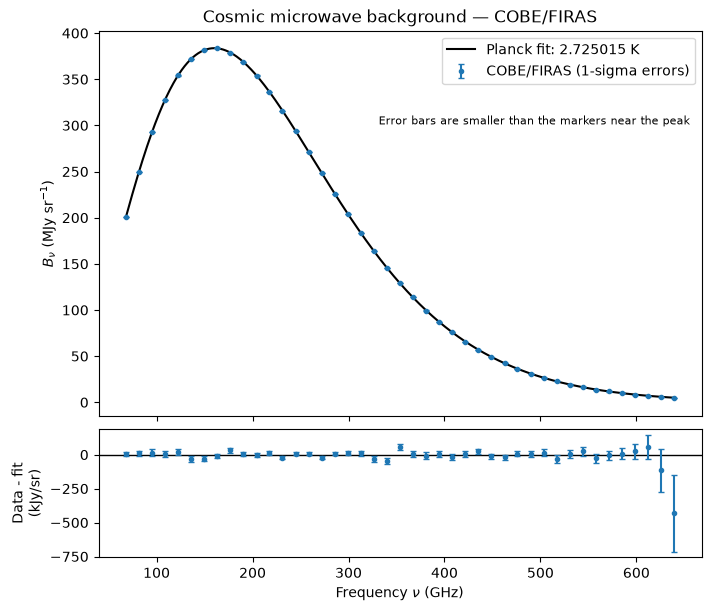

In [5]:
def planck_nu(frequency, temperature):
    """B_nu in W m^-2 Hz^-1 sr^-1; frequency in Hz, temperature in K."""
    frequency = np.asarray(frequency, dtype=float)
    return (2 * h * frequency**3 / c**2) / np.expm1(h * frequency / (k_B * temperature))


frequencies_hz = firas[:, 0] * 100 * c
intensity_si = firas[:, 1] * 1e-20
uncertainty_si = firas[:, 3] * 1e-23
assert np.all(uncertainty_si > 0)
parameters, covariance = curve_fit(planck_nu, frequencies_hz, intensity_si,
                                   p0=[2.725], sigma=uncertainty_si, absolute_sigma=True)
T_fit = parameters[0]
T_std = np.sqrt(covariance[0, 0])
assert abs(T_fit - 2.725) < 0.002
assert np.isfinite(T_std) and T_std > 0
residual_si = intensity_si - planck_nu(frequencies_hz, T_fit)
chi_squared = np.sum((residual_si / uncertainty_si)**2)
dof = len(firas) - len(parameters)
print(f"CMB temperature: T = {T_fit:.9f} +/- {T_std:.9f} K (formal 1-sigma)")
print(f"chi^2 / dof = {chi_squared:.2f} / {dof} = {chi_squared / dof:.3f}")

fig, (ax, residual_ax) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                                     gridspec_kw={"height_ratios": [3, 1]}, layout="constrained")
grid_hz = np.linspace(frequencies_hz.min(), frequencies_hz.max(), 600)
ax.plot(grid_hz / 1e9, planck_nu(grid_hz, T_fit) / 1e-20,
        color="black", label=f"Planck fit: {T_fit:.6f} K")
ax.errorbar(frequencies_hz / 1e9, intensity_si / 1e-20, yerr=uncertainty_si / 1e-20,
            fmt="o", ms=3, capsize=2, label="COBE/FIRAS (1-sigma errors)")
ax.set(ylabel=r"$B_\nu$ (MJy sr$^{-1}$)", title="Cosmic microwave background — COBE/FIRAS")
ax.text(0.98, 0.78, "Error bars are smaller than the markers near the peak",
        transform=ax.transAxes, ha="right", va="top", fontsize=8)
ax.legend()
residual_ax.axhline(0, color="black", lw=1)
residual_ax.errorbar(frequencies_hz / 1e9, residual_si / 1e-23,
                     yerr=uncertainty_si / 1e-23, fmt="o", ms=3, capsize=2)
residual_ax.set(xlabel=r"Frequency $\nu$ (GHz)", ylabel="Data - fit\n(kJy/sr)")
plt.show()

## 5. Thử thêm / *Try this*

- Đổi `T` ở phần 1 thành 2700 K hoặc 10000 K: đỉnh phổ và công suất phát thay đổi ra sao?
  *Change `T` in section 1 to 2700 K or 10000 K: how do the peak and emitted power change?*
- Thay mẫu số `np.expm1(x)` bằng `np.exp(x)` trong `planck_nu` để chỉ khớp định luật Wien; so sánh phần dư ở tần số thấp và cao.
  *Replace the denominator `np.expm1(x)` with `np.exp(x)` in `planck_nu` to fit Wien's law alone; compare residuals at low and high frequencies.*
- Trong phép fit CMB, chỉ giữ nửa số điểm ở tần số cao: $T$ và sai số hình thức thay đổi thế nào?
  *In the CMB fit, keep only the higher-frequency half of the points: how do $T$ and its formal uncertainty change?*